# Modelo: arquitectura, entrenamiento y evaluación

Proyecto final — Tecnicatura en Ciencias de Datos. Bimestre 1 (local).

**Objetivo.** Mostrar el modelo entrenado y sus resultados. El entrenamiento no se ejecuta
en este notebook: se corrió con `python -m src.models.train`, porque SageMaker requiere un
script. Acá se carga el modelo ya guardado y se reutilizan las funciones de `src/`, sin
duplicar código.

| Sección | Qué muestra |
|---|---|
| 1. El modelo | Qué partes vienen preentrenadas, cuál se entrenó y cómo recorre una imagen |

---
## 0. Setup

Mismo setup que los notebooks anteriores. Requiere `models/model.pth`, que se genera con
`train.py` y no se versiona.

`evaluate.py` configura matplotlib para ejecutarse sin pantalla, como en SageMaker. La línea
`%matplotlib inline`, posterior a los imports, vuelve a habilitar los gráficos en el
notebook.

In [1]:
from pathlib import Path
import sys

REPO_DIR = str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

import matplotlib.pyplot as plt
import pandas as pd
import torch
from dotenv import load_dotenv
from PIL import Image

from src.data import eda
from src.data.augmentation import get_eval_pipeline
from src.data.dataset import CLASES
from src.data.preprocessing import split_dataset
from src.models.architecture import build_model
from src.models.evaluate import cargar_modelo

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
MODEL_DIR = Path(REPO_DIR) / "models"

In [2]:
load_dotenv(Path(REPO_DIR) / ".env")
import kagglehub

ruta_dataset = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
df_train, df_val, df_test = split_dataset(eda.listar_imagenes(ruta_dataset))
print(f"train: {len(df_train):,} | val: {len(df_val):,} | test: {len(df_test):,}")

train: 4,909 | val: 701 | test: 1,403


---
## 1. El modelo

EfficientNet-B0 fue entrenada previamente con más de un millón de fotografías generales
(ImageNet). Ese entrenamiento le permite reconocer patrones visuales: bordes, texturas y
formas. El proyecto reutiliza ese conocimiento y solo entrena la última capa, que decide a
cuál de las 4 clases corresponde una imagen (*transfer learning* con el backbone congelado).

### 1.1 Qué se entrenó y qué no

Un **parámetro** es un número interno que el modelo ajusta al aprender. En PyTorch, el
atributo `requires_grad` indica si ese número puede modificarse durante el
entrenamiento.

In [3]:
model = cargar_modelo(MODEL_DIR)
model.eval()

partes = {
    "features (backbone)": model.features,
    "avgpool": model.avgpool,
    "classifier (capa final)": model.classifier,
}
tabla = pd.DataFrame(
    {
        nombre: {
            "parámetros": sum(p.numel() for p in parte.parameters()),
            "entrenables": sum(p.numel() for p in parte.parameters() if p.requires_grad),
        }
        for nombre, parte in partes.items()
    }
).T
tabla.loc["TOTAL"] = tabla.sum()
print(f"Entrenables: {tabla.loc['TOTAL', 'entrenables'] / tabla.loc['TOTAL', 'parámetros']:.2%} del total")
tabla

Entrenables: 0.13% del total


,parámetros,entrenables
features (backbone),4007548,0
avgpool,0,0
classifier (capa final),5124,5124
TOTAL,4012672,5124


**Lectura.** Solo se entrenan 5.124 de los 4.012.672 parámetros. El número surge de la capa
final: recibe 1.280 valores y produce 4 puntajes, es decir 1.280 × 4 pesos más 4 términos
independientes (uno por clase). Por eso el entrenamiento es viable en CPU.

### 1.2 Verificación: el backbone no cambió

Que el backbone esté configurado como congelado no demuestra que haya quedado intacto. Sus
capas BatchNorm también guardan estadísticas que pueden actualizarse aunque los pesos estén
fijos; `train.modo_entrenamiento()` lo evita. Para comprobarlo, comparo cada valor del
backbone entrenado con el original de ImageNet.

In [4]:
original = build_model(num_classes=len(CLASES), pretrained=True).features.state_dict()
entrenado = model.features.state_dict()

distintos = [nombre for nombre in original if not torch.equal(original[nombre], entrenado[nombre])]
print(f"Componentes del backbone comparados: {len(original)}")
print(f"Componentes que cambiaron: {len(distintos)}")

Componentes del backbone comparados: 358
Componentes que cambiaron: 0


### 1.3 El recorrido de una imagen

Sigo una imagen de validación a través del modelo. Cada paso la resume: de una grilla de
píxeles a 4 puntajes, uno por clase. El modelo devuelve puntajes sin escala (*logits*); la
función *softmax* los convierte en probabilidades que suman 1.

In [5]:
ejemplo = df_val[df_val["clase"] == "glioma"].iloc[0]
imagen = Image.open(ejemplo["path"]).convert("RGB")
entrada = get_eval_pipeline()(imagen).unsqueeze(0)  # agrega la dimensión del batch: (1, 3, 224, 224)

with torch.no_grad():
    mapas = model.features(entrada)
    resumen = torch.flatten(model.avgpool(mapas), 1)
    logits = model.classifier(resumen)
    proba = torch.softmax(logits, dim=1)
    # El recorrido paso a paso tiene que dar lo mismo que llamar al modelo completo.
    assert torch.allclose(logits, model(entrada))

pd.DataFrame(
    [
        ("Imagen de entrada", tuple(entrada.shape), "1 imagen, 3 canales, 224 × 224 píxeles"),
        ("Después de features", tuple(mapas.shape), "1.280 mapas de patrones de 7 × 7"),
        ("Después de avgpool", tuple(resumen.shape), "Cada mapa resumido en un número"),
        ("Después de classifier", tuple(logits.shape), "Un puntaje por clase"),
    ],
    columns=["Paso", "Forma", "Significado"],
)

,Paso,Forma,Significado
0,Imagen de entrada,"(1, 3, 224, 224)","1 imagen, 3 canales, 224 × 224 píxeles"
1,Después de features,"(1, 1280, 7, 7)",1.280 mapas de patrones de 7 × 7
2,Después de avgpool,"(1, 1280)",Cada mapa resumido en un número
3,Después de classifier,"(1, 4)",Un puntaje por clase


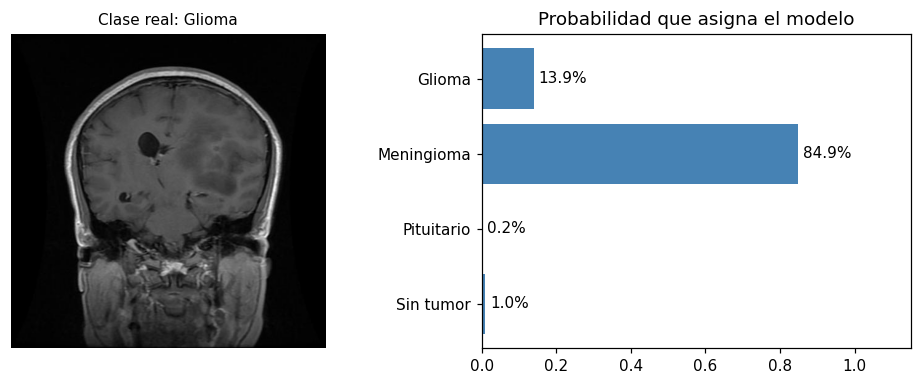

In [6]:
fig, (ax_img, ax_proba) = plt.subplots(1, 2, figsize=(9, 3.6))
ax_img.imshow(imagen)
ax_img.set_title(f"Clase real: {eda.ETIQUETAS[ejemplo['clase']]}", fontsize=10)
ax_img.axis("off")

barras = ax_proba.barh([eda.ETIQUETAS[c] for c in CLASES], proba[0].tolist(), color="steelblue")
ax_proba.bar_label(barras, labels=[f"{p:.1%}" for p in proba[0].tolist()], padding=3)
ax_proba.invert_yaxis()
ax_proba.set(title="Probabilidad que asigna el modelo", xlim=(0, 1.15))
plt.tight_layout()
plt.show()

**Lectura.** La clase con mayor probabilidad es la predicción. En este caso el modelo se
equivoca: es un glioma y le asigna 84,9% a meningioma, la confusión más frecuente del
proyecto (ver `docs/model_card.md`). Detecta que hay un tumor (1,0% para "Sin tumor"), pero
no acierta el tipo. También muestra que una probabilidad alta no garantiza una predicción
correcta.

Es un único caso, elegido por su posición en la lista y no por su resultado: ilustra el
mecanismo y no mide el desempeño del modelo.